<a href="https://colab.research.google.com/github/balasubramanh-blip/Info450F26A/blob/main/Info45010_20_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('/content/loan_data.csv')

In [4]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


<Axes: >

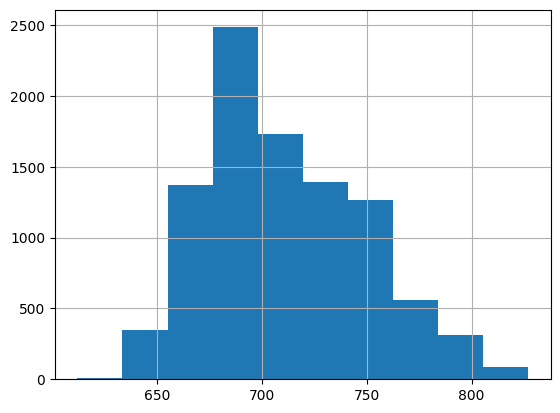

In [5]:
df['fico'].hist()

Skew

+ right +

- left -

In [8]:
print(df['fico'].mean())
print(df['fico'].median())
print(df['fico'].skew())
print(df['fico'].kurt())

710.8463144706619
707.0
0.4712597399323796
-0.42231231029396055


Pareto Analysis (80/20 rule)

In [10]:
pareto=df.groupby('purpose')['not.fully.paid'].sum().sort_values(ascending=False).reset_index()

In [12]:
pareto['pct']=pareto['not.fully.paid']/pareto['not.fully.paid'].sum()*100

In [13]:
pareto

,purpose,not.fully.paid,pct
0,debt_consolidation,603,39.334638
1,all_other,387,25.244618
2,small_business,172,11.219830
3,credit_card,146,9.523810
4,home_improvement,107,6.979778
5,educational,69,4.500978
6,major_purchase,49,3.196347


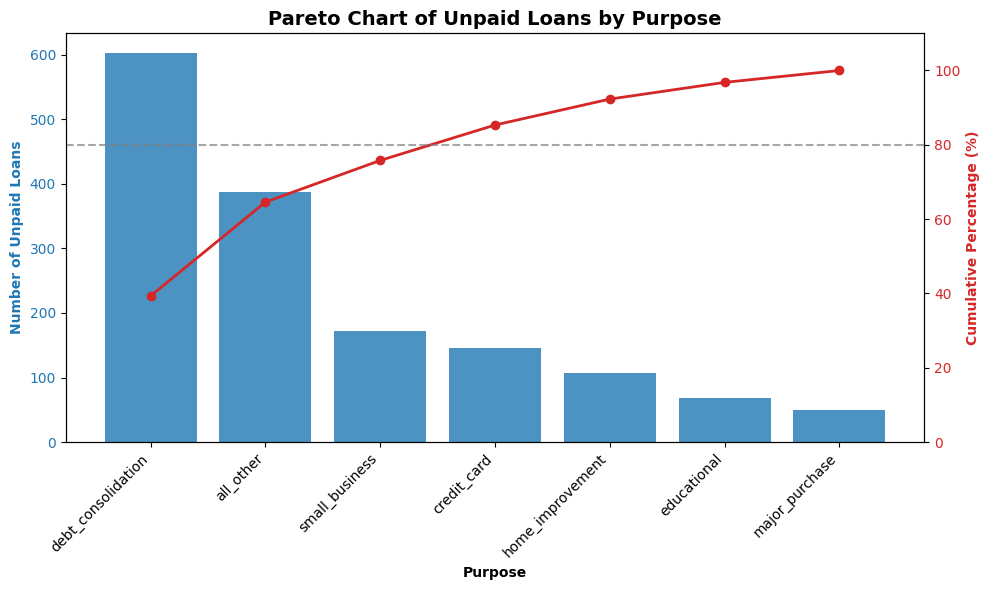

In [15]:
import matplotlib.pyplot as plt

# Calculate cumulative percentage
pareto['cum_pct'] = pareto['pct'].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar chart for counts
color = 'tab:blue'
ax1.set_xlabel('Purpose', fontweight='bold')
ax1.set_ylabel('Number of Unpaid Loans', color=color, fontweight='bold')
bars = ax1.bar(pareto['purpose'], pareto['not.fully.paid'], color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)

# Set ticks and labels properly to avoid UserWarning
ax1.set_xticks(range(len(pareto['purpose'])))
ax1.set_xticklabels(pareto['purpose'], rotation=45, ha='right')

# Line chart for cumulative percentage on a twin axis
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Cumulative Percentage (%)', color=color, fontweight='bold')
line = ax2.plot(pareto['purpose'], pareto['cum_pct'], color=color, marker='o', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 110)

# Add an 80% threshold line
ax2.axhline(80, color='gray', linestyle='--', alpha=0.7, label='80% Threshold')

plt.title('Pareto Chart of Unpaid Loans by Purpose', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

Cohens D
$$d=/frac{mean1-mean2}-{pooled s}$$

if d is around .2 - not much difference

if d is around .5 - kinda difference

if d is like 8 or more -  different

In [16]:
df.groupby('not.fully.paid')['fico'].agg(["mean","std"])

,mean,std
not.fully.paid,,
0,713.326911,38.223723
1,697.828441,33.756808


In [17]:
# Group the FICO scores by the not.fully.paid column
group_0 = df[df['not.fully.paid'] == 0]['fico']
group_1 = df[df['not.fully.paid'] == 1]['fico']

# Calculate means
mean0 = group_0.mean()
mean1 = group_1.mean()

# Calculate sample sizes
n0 = len(group_0)
nn1 = len(group_1)

# Calculate sample variances
var0 = group_0.var()
var1 = group_1.var()

# Calculate pooled standard deviation
pooled_std = np.sqrt(((n0 - 1) * var0 + (nn1 - 1) * var1) / (n0 + nn1 - 2))

# Calculate Cohen's d
cohens_d = (mean0 - mean1) / pooled_std

print(f"Group 0 (Fully Paid) Mean FICO: {mean0:.4f}")
print(f"Group 1 (Not Fully Paid) Mean FICO: {mean1:.4f}")
print(f"Pooled Standard Deviation: {pooled_std:.4f}")
print(f"Cohen's d: {cohens_d:.4f}")

Group 0 (Fully Paid) Mean FICO: 713.3269
Group 1 (Not Fully Paid) Mean FICO: 697.8284
Pooled Standard Deviation: 37.5448
Cohen's d: 0.4128
